![Banner](../images/09_04_banner_rs_uav.png)


# Crop Health: SAM Plant Masks and Senescence Detection

Yellowing leaves signal nitrogen deficiency, disease, water stress or simply the approach of
maturity.


## Overview

Mapping yellowing leaves from RGB imagery takes two steps: separate **plant from background** (in flooded rice the background is water, mud and glare), then split plant pixels into **green and senescent**. The LUMS study did the first with the Segment Anything Model (SAM), prompted automatically with Excess-Green seed points, and the second with the SegVeg pixel classifier followed by an HSV filter. This notebook rebuilds that pipeline with `rs.uav.sam_plant_mask`, `classify_senescence`, `hsv_filter`, `health_map` and `health_summary`, with model-free fallbacks so it runs without downloading any weights.


## Core concepts

### Learning objectives

1. Build plant masks with ExG + Otsu and understand where they fail.
2. Generate SAM prompts from colour (positive ExG seeds, negative soil/water/glare points)
   and run SAM on a frame (`sam_plant_mask`) or a GeoTIFF (`sam_segment`).
3. Classify plant pixels as green or senescent with a colour rule or a SegVeg-style
   classifier, and clean the result with an HSV filter.
4. Map health tile by tile over a large image and summarise yellow-leaf fraction per plot.
5. Follow the senescent fraction through the season.

### Data

| Data | Type |
|---|---|
| LUMS rice frames: 28 Aug for early health, then late September and October (`Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping`) | **Real** (CC BY 4.0) |
| 27 Aug orthomosaic used in the paper | **Real**, optional Google Drive download |

### Contents

1. Setup
2. Plant masks from colour
3. SAM with automatic prompts
4. Green or senescent?
5. A SegVeg-style pixel classifier
6. Large images: tiled health maps and per-plot summaries
7. The season in yellow
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colours

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)
from geolattice.rsense.uav import health  # lower-level helpers (prompt_points, colour_rule)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
LUMS = Path("../../../../Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RUN_SAM = False      # True: download SAM ViT-B (about 375 MB) and segment with it
SEGVEG_PKL = None    # path to a SegVeg pickle (model_scikit / XGBoost), if you have one
HEALTH_CMAP = ListedColormap(["#d9d0c1", "#2e7d32", "#e0b000"])  # background, green, senescent

late = sorted((LUMS / "2025-10-01").glob("*.png"))
img = rs.uav.read_frame(late[2], max_dim=1600)
rgb8 = rs.uav.to_rgb_array(img, uint8=True)
print(img.shape, late[2].name)

(3, 900, 1600) frame276.png


## Plant masks from colour

`rs.uav.exg_plant_mask` thresholds Excess Green with Otsu and cleans the mask (morphological
open/close, small components removed). It is fast and needs no model, but it inherits ExG's
weakness: **yellow leaves have low ExG**, so they drop out of the "plant" mask, exactly the
pixels this notebook is trying to find.


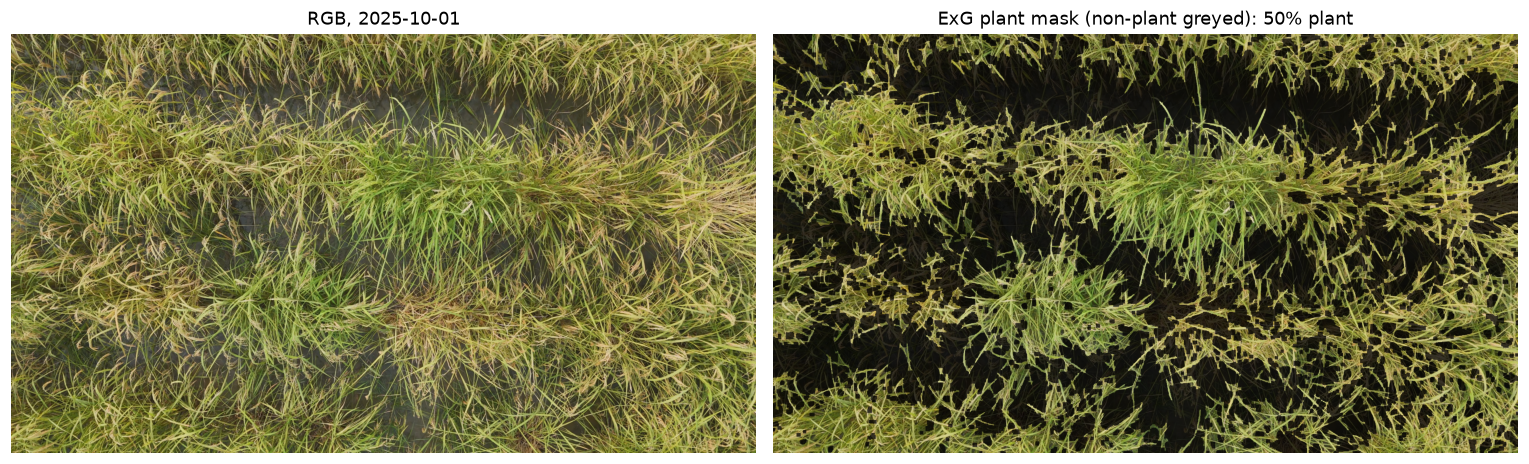

In [2]:
m_exg = rs.uav.exg_plant_mask(img, min_area=300)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].imshow(rgb8); axes[0].set_title(f"RGB, {late[2].parent.name}")
axes[1].imshow(rgb8); axes[1].imshow(np.ma.masked_equal(m_exg, 1), cmap="gray", alpha=0.75)
axes[1].set_title(f"ExG plant mask (non-plant greyed): {m_exg.mean():.0%} plant")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## SAM with automatic prompts

SAM segments "objects" given prompt points but has no idea what a plant is. LUMS seeded it
automatically: **positive** points where ExG is high and saturated (certainly vegetation),
**negative** points where it is low (soil, water) or bright and grey (glare), spread over the
image so no region is missed. `health.prompt_points` reproduces this; `rs.uav.sam_plant_mask`
runs SAM with those prompts and keeps the mask that covers the most positives and fewest
negatives.


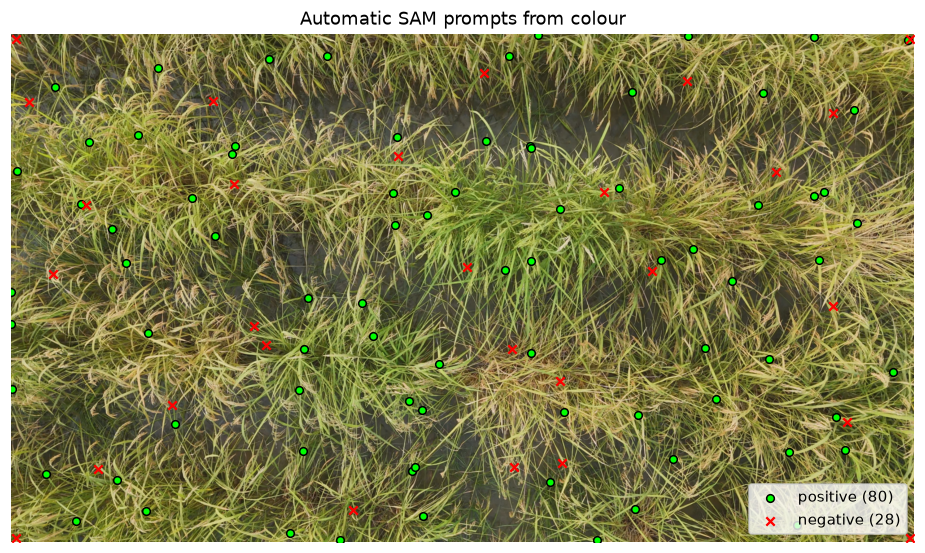

In [3]:
pos, neg = health.prompt_points(rgb8, n_pos=80, n_neg=24)
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(rgb8)
ax.scatter(pos[:, 0], pos[:, 1], c="lime", s=25, edgecolors="k", label=f"positive ({len(pos)})")
ax.scatter(neg[:, 0], neg[:, 1], c="red", marker="x", s=30, label=f"negative ({len(neg)})")
ax.legend(loc="lower right"); ax.set_title("Automatic SAM prompts from colour"); ax.axis("off"); plt.show()

In [4]:
if RUN_SAM:
    ckpt = rs.uav.fetch_weights("sam_vit_b")  # Meta's ViT-B checkpoint, Apache-2.0
    m_sam = rs.uav.sam_plant_mask(img, ckpt, model_type="vit_b", max_dim=1024)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    axes[0].imshow(m_exg, cmap="Greens"); axes[0].set_title(f"ExG mask {m_exg.mean():.0%}")
    axes[1].imshow(m_sam, cmap="Greens"); axes[1].set_title(f"SAM mask {m_sam.mean():.0%}")
    for a in axes: a.axis("off")
    plt.show()
    print("agreement:", float((m_sam == m_exg).mean()))
else:
    m_sam = None
    print("RUN_SAM is False: a colour-based mask is used below. With SAM, yellow leaves attached to a")
    print("plant are kept in the mask because SAM segments whole objects, not colours.")

RUN_SAM is False: a colour-based mask is used below. With SAM, yellow leaves attached to a
plant are kept in the mask because SAM segments whole objects, not colours.


For georeferenced orthomosaics, `rs.uav.sam_segment(path, mode=...)` wraps
`segment-geospatial` and writes a mask GeoTIFF (and optionally polygons). Modes: `"auto"`
(everything), `"points"` / `"boxes"` (prompts in map coordinates) and `"text"` (Grounding
DINO + SAM, e.g. `text_prompt="rice plant"`). It validates prompts before loading any model:


In [5]:
for kwargs in [dict(mode="points"), dict(mode="text")]:
    try:
        rs.uav.sam_segment(OUT / "example_ortho.tif", **kwargs)
    except (ValueError, TypeError, ImportError, FileNotFoundError) as e:
        print(f"{kwargs}: {type(e).__name__}: {e}")

{'mode': 'points'}: ValueError: mode='points' needs points=[[x, y], ...] in map coordinates
{'mode': 'text'}: ValueError: mode='text' needs text_prompt=


## Green or senescent?

`rs.uav.classify_senescence(image, plant_mask)` labels each plant pixel **1 = green** or
**2 = senescent** (0 = background). Without a model it uses a colour rule: hue on the green
side of yellow (above `hue_max` degrees) and positive ExG means green.

**Calibrate `hue_max` on your own data.** Camera colour processing and crop variety move the
hue of "green" a lot. The histogram below shows hue for saturated, reasonably bright pixels on
a mid-season date (green canopy) and on 3 October (mixed green and straw): late-season green
rice here is olive, at 65-80°, and yellow leaves sit at 45-55°. The package default of 75°
would call most olive leaves senescent. Otsu's method on the late-season hue picks the cut
between the two modes.


Otsu hue threshold on 3 Oct plant pixels: 62 degrees


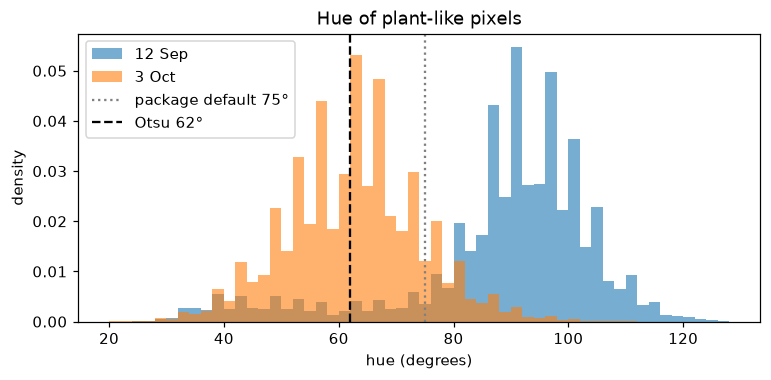

In [6]:
import cv2
from skimage.filters import threshold_otsu

def plant_hues(paths):
    """Hue (degrees) of saturated, not-dark pixels across frames."""
    out = []
    for f in paths:
        rgb = rs.uav.to_rgb_array(rs.uav.read_frame(f, max_dim=800), uint8=True)
        hsv_full = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL).astype(float)
        m = (hsv_full[..., 1] > 60) & (hsv_full[..., 2] > 70)
        out.append(hsv_full[..., 0][m] * 360 / 255)
    return np.concatenate(out)

h_mid = plant_hues(sorted((LUMS / "2025-09-12").glob("*.png"))[:5])
h_late = plant_hues(sorted((LUMS / "2025-10-03").glob("*.png"))[:5])
h_late_sel = h_late[(h_late > 30) & (h_late < 110)]
HUE = float(round(threshold_otsu(h_late_sel)))
print(f"Otsu hue threshold on 3 Oct plant pixels: {HUE:.0f} degrees")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(20, 130, 2)
ax.hist(h_mid, bins=bins, alpha=0.6, density=True, label="12 Sep")
ax.hist(h_late, bins=bins, alpha=0.6, density=True, label="3 Oct")
ax.axvline(75, color="grey", ls=":", label="package default 75°")
ax.axvline(HUE, color="k", ls="--", label=f"Otsu {HUE:.0f}°")
ax.set(xlabel="hue (degrees)", ylabel="density", title="Hue of plant-like pixels"); ax.legend(); plt.show()

Because the ExG mask drops yellow leaves, the classification below runs on a looser mask:
anything saturated and not dark (which excludes water, shadow and glare but keeps straw-
coloured leaves).


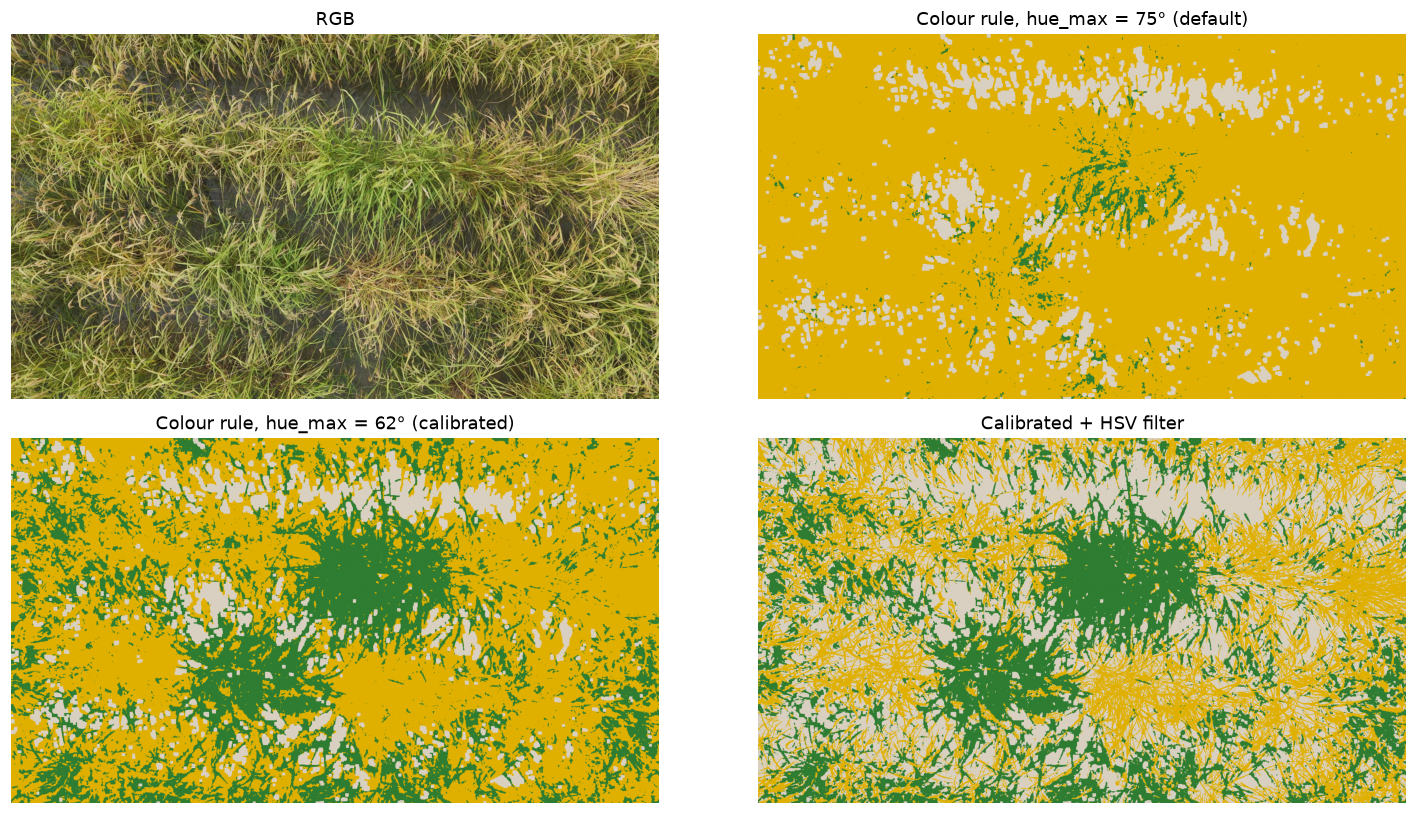

,,zone,pixels,plant_cover,green_frac,senescent_frac
default 75°,0,1,1440000,0.882,0.026,0.974
calibrated 62°,0,1,1440000,0.882,0.325,0.675
calibrated + HSV filter,0,1,1440000,0.612,0.468,0.532


In [7]:
hsv = cv2.cvtColor(rgb8, cv2.COLOR_RGB2HSV)
loose = health.clean_mask((hsv[..., 1] > 60) & (hsv[..., 2] > 70), min_area=300)  # saturated, not dark
plant_mask = m_sam if m_sam is not None else loose
labels75, _ = rs.uav.classify_senescence(img, plant_mask)  # package default, 75 degrees
labels, p_green = rs.uav.classify_senescence(img, plant_mask, hue_max=HUE)
labels_hsv = rs.uav.hsv_filter(img, labels, s_min=50, v_min=120)

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
axes[0, 0].imshow(rgb8); axes[0, 0].set_title("RGB")
axes[0, 1].imshow(labels75, cmap=HEALTH_CMAP, vmin=0, vmax=2); axes[0, 1].set_title("Colour rule, hue_max = 75° (default)")
axes[1, 0].imshow(labels, cmap=HEALTH_CMAP, vmin=0, vmax=2); axes[1, 0].set_title(f"Colour rule, hue_max = {HUE:.0f}° (calibrated)")
axes[1, 1].imshow(labels_hsv, cmap=HEALTH_CMAP, vmin=0, vmax=2); axes[1, 1].set_title("Calibrated + HSV filter")
for a in axes.flat: a.axis("off")
plt.tight_layout(); plt.show()
pd.concat({"default 75°": rs.uav.health_summary(labels75), f"calibrated {HUE:.0f}°": rs.uav.health_summary(labels),
           "calibrated + HSV filter": rs.uav.health_summary(labels_hsv)}).round(3)

The HSV filter sends "senescent" pixels that are grey (low saturation) or dark (low value) to
background: those are shadows, mud and water rather than yellow leaves.


## A SegVeg-style pixel classifier

SegVeg (Serouart et al. 2022) classifies vegetation pixels as green or senescent with a
gradient-boosting model on 14 colour features (RGB, HSV, Lab, chromatic coordinates and
more). `rs.uav.segveg_features` computes them, `rs.uav.load_segveg` loads the published
pickle, and `classify_senescence(model=...)` accepts any classifier with `predict_proba`.

The original pickle is not distributed here. To show the plug-in point, the cell below trains
a small XGBoost model on **pseudo-labels** from the colour rule on one frame and applies it
to another. It learns to imitate the rule (it cannot be better than its labels); a real
SegVeg model, trained on hand-labelled pixels, is what makes this step worth doing.


trained on 60000 pixels; 50% green


agreement with the colour rule on plant pixels: 100.0%


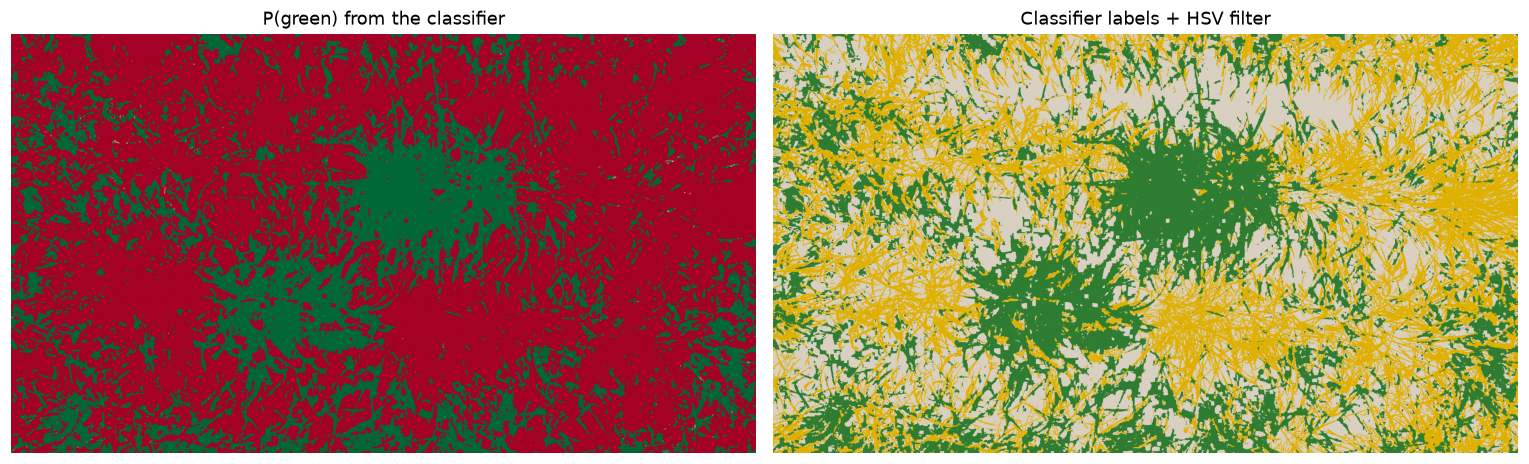

In [8]:
if SEGVEG_PKL:
    model = rs.uav.load_segveg(SEGVEG_PKL)
else:
    from xgboost import XGBClassifier

    train = rs.uav.to_rgb_array(rs.uav.read_frame(late[0], max_dim=800), uint8=True)
    tlab, _ = rs.uav.classify_senescence(train, None, hue_max=HUE)  # calibrated colour rule on every pixel
    X = rs.uav.segveg_features(train).reshape(-1, 14)
    y = (tlab.ravel() == 1).astype(int)  # 1 = green
    pick = np.random.default_rng(0).choice(len(y), 60_000, replace=False)
    model = XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.2, n_jobs=4).fit(X[pick], y[pick])
    print("trained on", len(pick), "pixels;", f"{y.mean():.0%} green")

lab_ml, p_ml = rs.uav.classify_senescence(img, plant_mask, model=model, threshold=0.5)
lab_ml = rs.uav.hsv_filter(img, lab_ml, s_min=50, v_min=120)
both = plant_mask.astype(bool)
print(f"agreement with the colour rule on plant pixels: {(lab_ml[both] == labels_hsv[both]).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].imshow(p_ml, cmap="RdYlGn", vmin=0, vmax=1); axes[0].set_title("P(green) from the classifier")
axes[1].imshow(lab_ml, cmap=HEALTH_CMAP, vmin=0, vmax=2); axes[1].set_title("Classifier labels + HSV filter")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Large images: tiled health maps and per-plot summaries

`rs.uav.health_map` runs mask → classify → HSV filter on overlapping tiles (LUMS: 2048 px with
256 px overlap) and combines tiles with a pixel-wise maximum, so a pixel called senescent by
either tile stays senescent. `mask_method="sam"` uses SAM when `sam_checkpoint` is given,
`"exg"` the ExG mask, and `"none"` classifies every pixel and relies on the HSV filter to
drop water, mud and shadow (used here, since the ExG mask would remove the yellow leaves). `health_summary(labels, zones)` reports cover and green/senescent
fractions per zone, here a 4 × 6 grid standing in for plots.


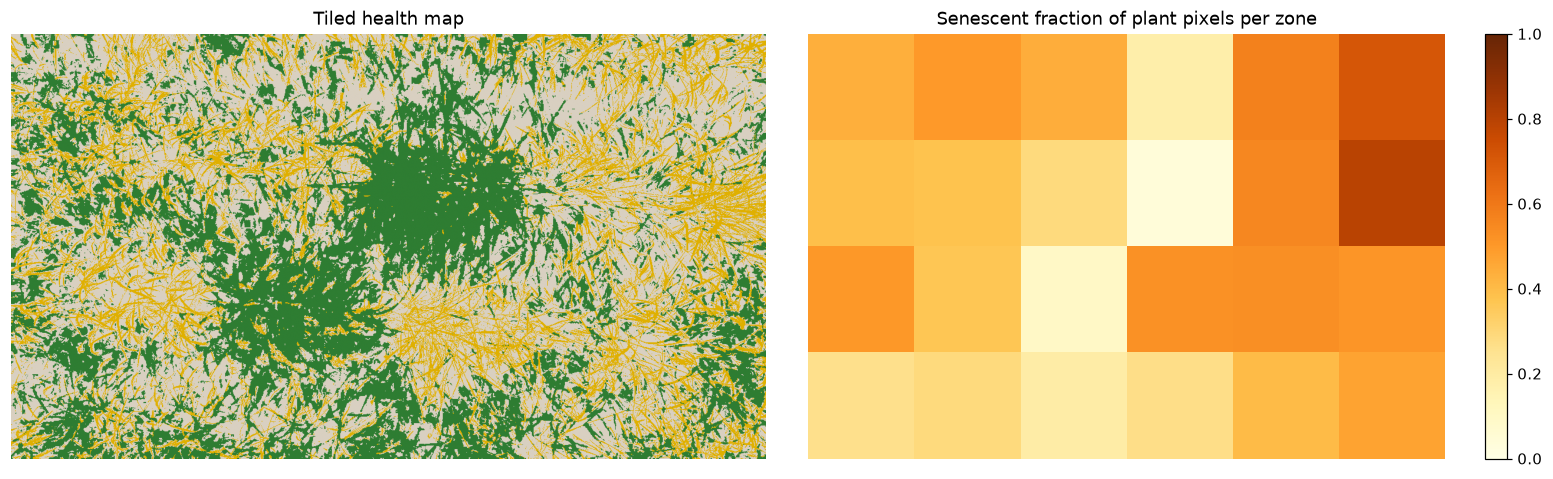

In [9]:
full = rs.uav.read_frame(late[2])  # 3840 x 2160
hm = rs.uav.health_map(full, tile=2048, overlap=256, mask_method="none", hue_max=HUE)  # SAM: sam_checkpoint=...
rows_, cols_ = hm.shape
zones = (np.arange(rows_)[:, None] * 4 // rows_) * 6 + (np.arange(cols_)[None, :] * 6 // cols_) + 1
per_zone = rs.uav.health_summary(hm, zones)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].imshow(hm[::3, ::3], cmap=HEALTH_CMAP, vmin=0, vmax=2); axes[0].set_title("Tiled health map")
im = axes[1].imshow(per_zone.senescent_frac.to_numpy().reshape(4, 6), cmap="YlOrBr", vmin=0, vmax=1)
axes[1].set_title("Senescent fraction of plant pixels per zone"); plt.colorbar(im, ax=axes[1])
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## The season in yellow

Senescent fraction for every public frame, with the colour rule on the loose mask (yellow
leaves included) and on the ExG mask (yellow leaves largely excluded):


,crop,date,senescent_loose_mean,senescent_loose_std,senescent_loose_count,senescent_exg_mean,senescent_exg_std,senescent_exg_count
0,rice,2025-08-22,0.168,0.128,10,0.013,0.023,10
1,rice,2025-08-28,0.296,0.132,10,0.036,0.051,10
2,rice,2025-09-04,0.190,0.212,10,0.012,0.015,10
3,rice,2025-09-05,0.187,0.068,10,0.025,0.017,10
4,rice,2025-09-09,0.056,0.066,10,0.003,0.004,10
5,rice,2025-09-12,0.086,0.127,10,0.005,0.011,10
6,rice,2025-09-17,0.116,0.094,10,0.005,0.005,10
7,rice,2025-09-19,0.047,0.029,10,0.021,0.011,10
8,rice,2025-09-26,0.082,0.099,10,0.036,0.029,10
9,rice,2025-10-01,0.192,0.175,10,0.149,0.156,10


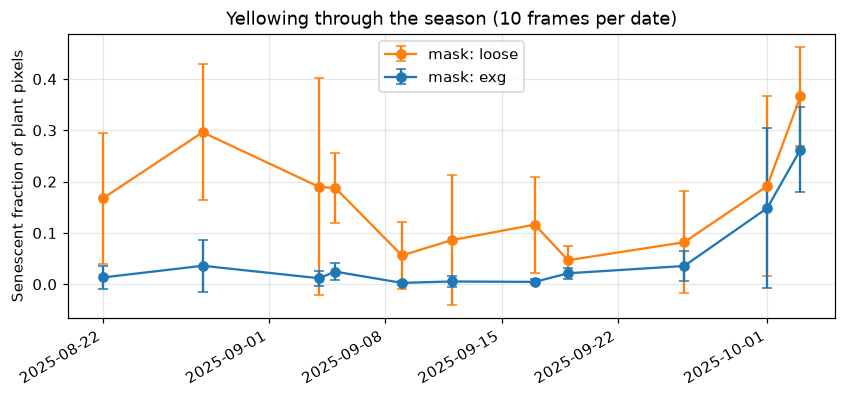

In [10]:
def health_traits(image):
    rgb = rs.uav.to_rgb_array(image, uint8=True)
    hsv_ = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    loose_ = health.clean_mask((hsv_[..., 1] > 60) & (hsv_[..., 2] > 70), min_area=200)
    out = {}
    for name, m in [("loose", loose_), ("exg", rs.uav.exg_plant_mask(image, min_area=200))]:
        lab, _ = rs.uav.classify_senescence(rgb, m, hue_max=HUE)
        s = rs.uav.health_summary(rs.uav.hsv_filter(rgb, lab, s_min=50, v_min=120)).iloc[0]
        out[f"senescent_{name}"] = s.senescent_frac
        out[f"plant_cover_{name}"] = s.plant_cover
    return out

cat = rs.uav.build_catalog(LUMS.parent)
cat = cat[cat.dataset.str.startswith("infra")].assign(crop="rice")
season = rs.uav.trait_table(cat, health_traits, max_dim=1024)
per_date = rs.uav.summarize_dates(season, ["senescent_loose", "senescent_exg"])
display(per_date.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, c in [("senescent_loose", "C1"), ("senescent_exg", "C0")]:
    ax.errorbar(per_date.date, per_date[f"{col}_mean"], yerr=per_date[f"{col}_std"], fmt="o-", color=c, capsize=3,
                label=col.replace("senescent_", "mask: "))
ax.set(ylabel="Senescent fraction of plant pixels", title="Yellowing through the season (10 frames per date)")
ax.legend(); ax.grid(alpha=0.3); fig.autofmt_xdate(); plt.show()
season.to_csv(OUT / "rice_senescence_frames.csv", index=False)

Three things show in the curves:

* With the loose mask, senescence is **low from 9 to 26 September and rises in October** (to
  about a third of plant pixels on 3 October) as the crop ripens.
* The **early values (22 Aug to 5 Sep) are not yellow leaves**: before the canopy closes, the
  loose mask also picks up dry soil and weeds between rows, and brown soil has the same hue
  as straw. A real plant mask (SAM, or a trained classifier) is needed early in the season.
* The **ExG mask stays near zero all season**, because it removes yellow leaves before they
  can be classified. This is why LUMS used SAM, which segments whole plants regardless of
  colour.


## Summary and exercises

**Key points**

- Health mapping is two splits: plant versus background, then green versus senescent.
- ExG + Otsu loses yellow leaves, glare and the boundary with water. SAM, prompted with ExG
  seeds and with points on soil, water and glare, holds that mask.
- The second split is a colour rule, an HSV filter, or a SegVeg-style classifier.
- Yellow-leaf fraction per plot, followed through the season, is the trait the map is for.

**GeoLattice functions used:** `rs.uav.exg_plant_mask`, `rs.uav.sam_plant_mask`, `rs.uav.sam_segment`,
`rs.uav.classify_senescence`, `rs.uav.hsv_filter`, `rs.uav.health_map`, `rs.uav.health_summary`,
`rs.uav.trait_table`, `rs.uav.summarize_dates`.

**Exercises**

1. Set `RUN_SAM = True` and compare SAM, ExG and loose masks on a late-season frame. Which
   keeps yellow leaves?
2. Re-run Section 7 with `hue_max` 5° above and below the calibrated value. How sensitive is
   the season curve? Is the early-season level driven by leaves or by dry soil?
3. Label 200 pixels by hand (green vs yellow) on one frame, train the XGBoost model on them
   instead of pseudo-labels, and compare with the colour rule.
4. Turn the 4 × 6 zone grid into polygons and export the per-zone table as a GeoPackage.

**References**

- Kirillov, A. et al. (2023). Segment Anything. *ICCV 2023*.
- Serouart, M. et al. (2022). SegVeg: segmenting RGB images into green and senescent
  vegetation by combining deep and shallow methods. *Plant Phenomics*, 2022, 9803570.
- Chaudhry, H., Rana, S. and Jaleel, A. (2026). *Computers and Electronics in Agriculture*
  (accepted).
- Wu, Q. and Osco, L. P. (2023). samgeo: a Python package for segmenting geospatial data with
  the Segment Anything Model. *Journal of Open Source Software*, 8, 5663.
